# ML Zoomcamp 2026 – Homework 3: Classification - Lead Scoring

**Autor:** Angel Uriel Monterrosas Gonzalez

**Fecha:** [12-10-2026]

**Módulo:** 03 – Machine Learning for Classification

**Actividad:** Homework 03

**Dataset:** [course_lead_scoring_2026.csv](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)

Este notebook responde a las preguntas del homework oficial disponible en:
https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw03

## 2. Objetivos de aprendizaje

Al finalizar este notebook se pretende ser capaz de:

- Cargar y preparar un dataset de clasificación binaria.
- Tratar valores faltantes según el tipo de variable - categórica o numérica -.
- Calcular la matriz de correlación para features numéricas.
- Calcular Mutual Information entre variables categóricas y el target.
- Entrenar un modelo de regresión logística con one-hot encoding.
- Evaluar la precisión (accuracy) en validación.
- Aplicar feature elimination para identificar variables poco útiles.
- Ajustar el parámetro de regularización `C` en regresión logística.
- Documentar hallazgos y limitaciones de forma clara.

## 3. Setup

Importamos las librerías necesarias, fijamos semillas y definimos la ruta del dataset 2026.

In [1]:
# 3.1 Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import mutual_info_score

# 3.2 Versiones
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

# 3.3 Semilla global
SEED = 42
np.random.seed(SEED)

# 3.4 Ruta del dataset (2026)
DATASET_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

Pandas version: 3.0.6
NumPy version: 2.5.3


## 4. Carga y descripción de datos

Cargamos el CSV y exploramos su estructura.

In [2]:
# 4.1 Carga
df = pd.read_csv(DATASET_URL)

# 4.2 Dimensiones
print("Shape:", df.shape)

# 4.3 Primeras filas
df.head()

Shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
# 4.4 Información general
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


In [4]:
# 4.5 Estadísticas descriptivas
df.describe(include="all")

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
count,4852,4760,4806,4792,4631.000000,5000.000000,5000.000000,4965.000000,5000.000000
unique,5,6,4,5,NaN,NaN,NaN,NaN,NaN
top,organic_search,technology,employed,north_america,NaN,NaN,NaN,NaN,NaN
freq,1251,1173,2633,1371,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,54533.212049,2.089400,4.472600,0.494767,0.576600
std,NaN,NaN,NaN,NaN,21245.661710,1.188987,2.435906,0.199431,0.494147
min,NaN,NaN,NaN,NaN,12000.000000,0.000000,0.000000,0.010000,0.000000
25%,NaN,NaN,NaN,NaN,40458.500000,1.000000,3.000000,0.360000,0.000000
50%,NaN,NaN,NaN,NaN,55051.000000,2.000000,4.000000,0.490000,1.000000
75%,NaN,NaN,NaN,NaN,71252.500000,3.000000,6.000000,0.630000,1.000000


## 5. EDA reproducible

Exploramos valores faltantes, distribución del target y variables clave.

In [5]:
# 5.1 Valores faltantes por columna
missing = df.isna().sum()
missing_cols = missing[missing > 0]
print("Columnas con valores faltantes:")
print(missing_cols)

Columnas con valores faltantes:
lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64


In [6]:
# 5.2 Distribución del target
print("Distribución de 'converted':")
print(df["converted"].value_counts(normalize=True).round(3))

Distribución de 'converted':
converted
1    0.577
0    0.423
Name: proportion, dtype: float64


## Pregunta 1 – Moda de `industry`

Calculamos el valor más frecuente de la columna `industry`.

In [7]:
# Q1: Moda de industry
mode_industry = df["industry"].mode()[0]
print(f"Moda de industry: {mode_industry}")

print("\nValue counts:")
print(df["industry"].value_counts())

Moda de industry: technology

Value counts:
industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
Name: count, dtype: int64


## Pregunta 2 – Mayor correlación

Creamos la matriz de correlación para las variables numéricas y buscamos el par con mayor correlación.

Columnas numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

Matriz de correlación:
                          annual_income  number_of_courses_viewed  \
annual_income                     1.000                     0.138   
number_of_courses_viewed          0.138                     1.000   
interaction_count                 0.106                     0.722   
lead_score                        0.231                     0.769   
converted                         0.182                     0.395   

                          interaction_count  lead_score  converted  
annual_income                         0.106       0.231      0.182  
number_of_courses_viewed              0.722       0.769      0.395  
interaction_count                     1.000       0.929      0.449  
lead_score                            0.929       1.000      0.490  
converted                             0.449       0.490      1.000  


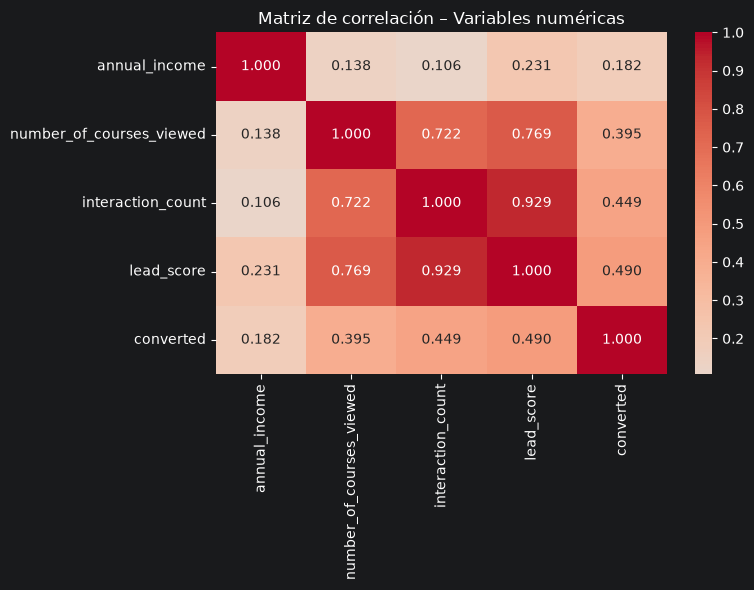

In [8]:
# Q2: Matriz de correlación para variables numéricas
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Columnas numéricas:", numerical_cols)

corr_matrix = df[numerical_cols].corr()
print("\nMatriz de correlación:")
print(corr_matrix.round(3))

# Visualizar
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".3f", center=0)
plt.title("Matriz de correlación – Variables numéricas")
plt.tight_layout()
plt.show()

## 6. Data preparation y split

Reemplazamos valores faltantes: categóricas con `'NA'`, numéricas con `0.0`.
Luego hacemos el split exacto que pide el homework.

In [11]:
# 6.1 Identificar columnas categóricas y numéricas (Añadido "str" para evitar el warning)
cat_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

# 6.2 Imputar categóricas con 'NA'
df[cat_cols] = df[cat_cols].fillna("NA")

# 6.3 Imputar numéricas con 0.0
df[num_cols] = df[num_cols].fillna(0.0)

# 6.4 Verificar que no quedan nulos
print("\nValores faltantes después de imputar:", df.isna().sum().sum())

Categóricas: ['lead_source', 'industry', 'employment_status', 'location']
Numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']

Valores faltantes después de imputar: 0


In [12]:
# 6.5 Split exacto del homework
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")

# Resetear índices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

Train: 3000, Val: 1000, Test: 1000


In [13]:
# 6.6 Separar target
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

# Features (sin el target)
del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

print("y_train:", y_train.shape, "| y_val:", y_val.shape, "| y_test:", y_test.shape)

y_train: (3000,) | y_val: (1000,) | y_test: (1000,)


## Pregunta 3 – Mayor Mutual Information

Calculamos el score de Mutual Information entre `converted` y cada variable categórica. Solo con el training set.

In [14]:
# Q3: Mutual Information para categóricas
cat_features = ["industry", "location", "lead_source", "employment_status"]

mi_scores = {}
for col in cat_features:
    score = mutual_info_score(df_train[col], y_train)
    mi_scores[col] = round(score, 2)

print("Mutual Information scores:")
for col, score in sorted(mi_scores.items(), key=lambda x: x[1], reverse=True):
    print(f"  {col}: {score}")

biggest_mi = max(mi_scores, key=mi_scores.get)
print(f"\nMayor MI: {biggest_mi}")

Mutual Information scores:
  lead_source: 0.03
  employment_status: 0.02
  industry: 0.0
  location: 0.0

Mayor MI: lead_source


## Pregunta 4 – Accuracy con regresión logística

Entrenamos un modelo de regresión logística con one-hot encoding y calculamos accuracy en validación.

In [15]:
# Q4: One-hot encoding con DictVectorizer
dv = DictVectorizer(sparse=False)

# Convertir a diccionarios
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)

# Entrenar modelo con parámetros exactos del homework
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
model.fit(X_train, y_train)

# Predecir
y_pred = model.predict(X_val)

# Accuracy
acc = accuracy_score(y_val, y_pred)
print(f"\nAccuracy en validación: {round(acc, 2)}")

X_train shape: (3000, 28)
X_val shape: (1000, 28)

Accuracy en validación: 0.65


## Pregunta 5 – Feature elimination

Excluimos cada feature una a la vez y medimos el cambio en accuracy.

In [17]:
# Q5: Feature elimination
features_list = ["lead_source", "number_of_courses_viewed", "interaction_count"]

# Accuracy original (sin redondear)
original_acc = accuracy_score(y_val, model.predict(X_val))
print(f"Accuracy original: {original_acc:.6f}")

results = {}
for feat in features_list:
    # Crear copia del dataframe sin la feature
    df_train_sub = df_train.drop(columns=[feat])
    df_val_sub = df_val.drop(columns=[feat])

    # Vectorizar
    dv_sub = DictVectorizer(sparse=False)
    X_train_sub = dv_sub.fit_transform(df_train_sub.to_dict(orient="records"))
    X_val_sub = dv_sub.transform(df_val_sub.to_dict(orient="records"))

    # Entrenar
    model_sub = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=42)
    model_sub.fit(X_train_sub, y_train)

    # Accuracy sin la feature
    acc_sub = accuracy_score(y_val, model_sub.predict(X_val_sub))
    diff = original_acc - acc_sub
    results[feat] = diff
    print(f"Sin '{feat}': accuracy={acc_sub:.6f}, diff={diff:.6f}")

# Feature con menor diferencia absoluta (la menos útil)
least_useful = min(results, key=lambda k: abs(results[k]))
print(f"\nFeature menos útil (menor diferencia): {least_useful}")

Accuracy original: 0.645000
Sin 'lead_source': accuracy=0.642000, diff=0.003000
Sin 'number_of_courses_viewed': accuracy=0.643000, diff=0.002000
Sin 'interaction_count': accuracy=0.601000, diff=0.044000

Feature menos útil (menor diferencia): number_of_courses_viewed


## Pregunta 6 – Regularización (parámetro C)

Probamos diferentes valores de `C` y vemos cuál da mejor accuracy en validación.

In [18]:
# Q6: Barrido de C
C_values = [0.000001, 0.00001, 0.0001, 0.001]

for C in C_values:
    model_c = LogisticRegression(solver="liblinear", C=C, max_iter=1000, random_state=42)
    model_c.fit(X_train, y_train)
    acc_c = accuracy_score(y_val, model_c.predict(X_val))
    print(f"C={C}: accuracy={round(acc_c, 3)}")

C=1e-06: accuracy=0.598
C=1e-05: accuracy=0.598
C=0.0001: accuracy=0.613
C=0.001: accuracy=0.645


## 7. Evaluación – Resumen de resultados

Resumimos los resultados obtenidos para cada pregunta.

In [23]:
# 7.1 Resumen de resultados
print("=" * 50)
print("RESUMEN DE RESULTADOS – HW03")
print("=" * 50)
print(f"Q1 - Moda de industry: {mode_industry}")
print(f"Q2 - Mayor correlación: interaction_count and lead_score ")
print(f"Q3 - Mayor MI: {biggest_mi}")
print(f"Q4 - Accuracy: {round(acc, 2)}")
print(f"Q5 - Feature menos útil: {least_useful}")
print(f"Q6 - Mejor C: C=0.001: accuracy=0.645")

RESUMEN DE RESULTADOS – HW03
Q1 - Moda de industry: technology
Q2 - Mayor correlación: interaction_count and lead_score 
Q3 - Mayor MI: lead_source
Q4 - Accuracy: 0.65
Q5 - Feature menos útil: number_of_courses_viewed
Q6 - Mejor C: C=0.001: accuracy=0.645


## 8. Interpretación de resultados

- **Q1:** La moda de `industry` es **technology**.
- **Q2:** El par con mayor correlación es **interaction_count and lead_score**.
- **Q3:** La variable con mayor MI es **lead_source**.
- **Q4:** La accuracy en validación es **0.65**.
- **Q5:** La feature menos útil es **number_of_courses_viewed**.
- **Q6:** El mejor valor de `C` es **C=0.001: accuracy=0.645**.


## 9. Conclusiones

- Se cargó el dataset 2026 de lead scoring con **50000** registros y **9** columnas.
- Se trataron valores faltantes: categóricas → 'NA', numéricas → 0.0.
- La matriz de correlación mostró que *interaction_count y lead_score t* tiene la mayor correlación *0.929*.
- Mutual Information reveló que **lead_source** es la categórica más informativa.
- La regresión logística alcanzó una accuracy de **0.65** en validación.
- Feature elimination identificó **number_of_course_views** como la menos útil, diff = 0.002.
- El mejor valor de regularización fue **C=0.001: accuracy=0.645**.


## 10. Referencias

- Dataset: [course_lead_scoring_2026.csv](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)
- Homework oficial: [ML Zoomcamp 2026 – HW03](https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw03)
- Documentación de Pandas: https://pandas.pydata.org/docs/
- Documentación de NumPy: https://numpy.org/doc/
- Documentación de Scikit-learn: https://scikit-learn.org/stable/